In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap
import geopandas as gpd

# Read Fuel Data

In [2]:
# read distribution data
distribution_data = pd.read_csv('//sce.eix.com/workgroup/SPE_DSA/Charles/IgnitionGoalSettingInput/Distribution_2015-2024.csv',low_memory=False)
# filter distribution data
distribution_data = distribution_data[(distribution_data['time']<='2025')]
# create a date column
distribution_data['Date'] = pd.to_datetime(distribution_data['time']).dt.strftime('%Y-%m-%d')
# create a year column
distribution_data['Year'] = pd.to_datetime(distribution_data['time']).dt.year

In [3]:
# read circuit lengths
circuitlengths = pd.read_excel("//sce.eix.com/workgroup/SPE_DSA/Charles/IgnitionGoalSettingInput/Q1_2025-_HFRA_Conductor_SumStat_Circuit.xlsx")
# filter for OH only
circuitlengths = circuitlengths[circuitlengths['Conductor Type'].str.contains('OH',na=False)]
# filter for HFRA only
circuitlengths = circuitlengths[circuitlengths['HFRA Tier'].notna()]
# remove blank circuits
circuitlengths = circuitlengths[circuitlengths['Circuit Name'].notna()]
# capitalize circuit names
circuitlengths['Circuit Name'] = circuitlengths['Circuit Name'].str.upper()
circuitlengths_map = circuitlengths.groupby(['Circuit Name','Circuit FLOC'])['Circuit Miles'].sum().reset_index()

In [4]:
# read forecast distribution data
dist_df_forecast = pd.read_csv('//sce.eix.com/workgroup/SPE_DSA/Charles/IgnitionGoalSettingMidput/Dist_Forecasts_2025.csv', low_memory=False)
# make sure Date is date string of Datetime
dist_df_forecast['Date'] = pd.to_datetime(dist_df_forecast['Datetime']).dt.strftime('%Y-%m-%d')

In [5]:
# for forecast data, groupby Date, Circuit, take the mean of FuelsIndex_max_FPI2
dist_df_forecast_agg = dist_df_forecast.groupby(['Date', 'Circuit'])['FuelsIndex_max_FPI2'].mean().reset_index()
# # for forecast data, groupby Date, Circuit, take the max of FuelsIndex_max_FPI2
# dist_df_forecast_agg = dist_df_forecast.groupby(['Date', 'Circuit'])['FuelsIndex_max_FPI2'].max().reset_index()
# merge with circuit lengths
dist_df_forecast_agg = dist_df_forecast_agg.merge(circuitlengths_map, left_on='Circuit', right_on='Circuit Name', how='left')
# locate rows where Circuit Miles is NaN and Circuit contains ambercrest and change value to 32.7754002840092
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('AMBERCREST', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['AMBERCREST',32.7754002840092]
# locate rows where Circuit Miles is NaN and Circuit contains aventura and change value to 15.7032769637841
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('AVENTURA', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['AVENTURA',15.7032769637841]
# locate rows where Circuit Miles is NaN and Circuit contains birchim and change value to 46.34484383
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('BIRCHIM', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['BIRCHIM',46.34484383]
# locate rows where Circuit Miles is NaN and Circuit contains cafe and change value to 27.6402669615555
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('CAFE', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['CAFE',27.6402669615555]
# locate rows where Circuit Miles is NaN and Circuit contains canebrake and change value to 66.16859376
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('CANEBRAKE', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['CANEBRAKE',66.16859376]
# locate rows where Circuit Miles is NaN and Circuit contains casals and change value to 0.446999553409736
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('CASALS', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['CASALS',0.446999553409736]
# locate rows where Circuit Miles is NaN and Circuit contains coachella and change value to 6.590021052
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('COACHELLA', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['COACHELLA',6.590021052]
# locate rows where circuit miles is NaN and circuit contains energy and change value to 32.37798311
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('ENERGY', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['ENERGY',32.37798311]
# locate rows where circuit miles is NaN and circuit contains fingal and change value to 36.6548594697613
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('FINGAL', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['FINGAL',36.6548594697613]
# locate rows where circuit miles is NaN and circuit contains guitar and change value to 42.2491638220717
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('GUITAR', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['GUITAR',42.2491638220717]
# locate rows where circuit miles is NaN and circuit contains huckleberry and change value to 25.4840533042463
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('HUCKLEBERRY', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['HUCKLEBERRY',25.4840533042463]
# locate rows where circuit miles is NaN and circuit contains Kinsey and change value to 38.2093922
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('KINSEY', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['KINSEY',38.2093922]
# locate rows where circuit miles is NaN and circuit contains Penstock and change value to 50.90351311
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('PENSTOCK', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['PENSTOCK',50.90351311]
# locate rows where circuit miles is NaN and circuit contains Shovel and change value to 47.51064986
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('SHOVEL', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['SHOVEL',47.51064986]
# locate rows where circuit miles is NaN and circuit contains Tejon and change value to 57.8330462
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('TEJON', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['TEJON',57.8330462]
# locate rows where circuit miles is NaN and circuit contains Toll and change value to 8.228283341
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('TOLL', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['TOLL',8.228283341]
# locate rows where circuit miles is NaN and circuit contains Sutt and change value to 16.8635623
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('SUTT', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['SUTT',16.8635623]
# locate rows where circuit miles is NaN and circuit contains POPPET FLATS and change value to 31.30335437
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('POPPET FLATS', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['POPPET FLATS',31.30335437]
# sort values by Date and Circuit Name and FuelsIndex_max_FPI2 descending
dist_df_forecast_agg = dist_df_forecast_agg.sort_values(by=['Date', 'Circuit Name', 'FuelsIndex_max_FPI2'], ascending=[True, True, False])
# # drop duplicate Date and Circuit Name, keep first one
dist_df_forecast_agg = dist_df_forecast_agg.drop_duplicates(subset=['Date', 'Circuit Name'], keep='first')

# Monthly Forecast

In [6]:
# read ignition data
ignitions = pd.read_excel("//sce.eix.com/workgroup/SPE_DSA/Charles/IgnitionGoalSettingInput/Ignition_Safari_Connection.xlsx")
# rename columns 
ignitions = ignitions.rename(columns={'Date/Time':'Date','Circuit Name':'Circuit_Name','Circuit ID':'Circuit_ID','Event ID':'Event_ID'})
# get year column
ignitions['Year'] = pd.to_datetime(ignitions['Date']).dt.year
# get month column
ignitions['Month'] = pd.to_datetime(ignitions['Date']).dt.month
# keep only SCE involved ignitions
ignitions = ignitions[ignitions['SCE Involved'].str.contains('yes|inconclusive',case=False,na=False)]
# keep only reportable ignitions
ignitions = ignitions[ignitions['CPUC Reportable']==1]
# for Status, ignore the ones that say open
ignitions = ignitions[~ignitions['Status'].str.contains('open', case=False, na=False)]
# only keep ones where Status says complete
ignitions = ignitions[ignitions['Status'].str.contains('complete', case=False, na=False)]
# keep only HFRA ignitions
ignitions = ignitions[ignitions['HFRA'].str.contains('T2|T3',na=False)]
# loc row where circuit name has 'banducci' and change Circuit_ID to ET-02156
ignitions.loc[ignitions['Circuit_Name'].str.contains('banducci', case=False, na=False), 'Circuit_ID'] = 'ET-02156'
# change date format
ignitions['Date'] = pd.to_datetime(ignitions['Date']).dt.strftime('%Y-%m-%d')
# from 2015 onward
ignitions = ignitions[ignitions['Year'] >= 2015]
# # before August 1 2025
# ignitions = ignitions[ignitions['Date'] < '2025-08-01']
# group by Year and get count of ignitions
ignitions = ignitions.groupby(['Year','Month']).agg({'Event_ID': 'count'}).reset_index().rename(columns={'Event_ID': 'Actual Ignitions'})
# create a dataframe with all months from 2015 to 2025
all_months = pd.DataFrame({'Year': np.repeat(range(2015, 2026), 12), 'Month': list(range(1, 13)) * 11})
# merge with ignitions to get all months
ignitions = all_months.merge(ignitions, on=['Year', 'Month'], how='left')
# fill na with 0
ignitions['Actual Ignitions'] = ignitions['Actual Ignitions'].fillna(0).astype(int)

In [7]:
ads_agg = 'mean_max'
fuel_var = f"{ads_agg}_fpi_2.0_tdd_fuels_index"
fuel_var2 = 'FuelsIndex_max_FPI2'
fuel_val = 0.85
# get distribution data before 2025 and 2025 onward
distribution_data_pre2025 = distribution_data[['Date','id',fuel_var,]].copy() 
distribution_data_2025 = dist_df_forecast_agg[['Date', 'Circuit', fuel_var2, 'Circuit Miles']].copy()
# rename columns
distribution_data_pre2025.rename(columns={'id': 'Circuit Name',}, inplace=True)
distribution_data_2025.rename(columns={'Circuit': 'Circuit Name', fuel_var2: fuel_var,}, inplace=True)
# merge with circuitlengths_map
distribution_data_pre2025 = distribution_data_pre2025.merge(circuitlengths_map, on='Circuit Name', how='left')
# drop the na Circuit Miles
distribution_data_pre2025 = distribution_data_pre2025[distribution_data_pre2025['Circuit Miles'].notna()]
cols_to_keep_cumsum = ['Date', 'Circuit Name', fuel_var, 'Circuit Miles']
# concat the two dataframes
distribution_data_cumsum = pd.concat([distribution_data_pre2025[cols_to_keep_cumsum], distribution_data_2025[cols_to_keep_cumsum]], ignore_index=True)
# drop the blank circuit miles
distribution_data_cumsum = distribution_data_cumsum[distribution_data_cumsum['Circuit Miles'].notna()]
# create a year and month column
distribution_data_cumsum['Year'] = pd.to_datetime(distribution_data_cumsum['Date']).dt.year
distribution_data_cumsum['Month'] = pd.to_datetime(distribution_data_cumsum['Date']).dt.month
# categorize fuel_var into above and below fuel_val
distribution_data_cumsum['Fuel Category'] = np.where((distribution_data_cumsum[fuel_var] >= fuel_val), f'High', 'Low')
# keep only High fuel category
distribution_data_cumsum = distribution_data_cumsum[distribution_data_cumsum['Fuel Category'] == 'High']
# group by Year and Month and sum Circuit Miles
distribution_data_cumsum = distribution_data_cumsum.groupby(['Year', 'Month']).agg({'Circuit Miles': 'sum'}).reset_index()
# create a dataframe with all months from 2015 to 2025
all_months = pd.DataFrame({'Year': np.repeat(range(2015, 2026), 12), 'Month': list(range(1, 13)) * 11})
# merge with distribution data to get all months
distribution_data_cumsum = all_months.merge(distribution_data_cumsum, on=['Year', 'Month'], how='left')
# fill na with 0
distribution_data_cumsum['Circuit Miles'] = distribution_data_cumsum['Circuit Miles'].fillna(0)

In [8]:
# read 2025 historical data for the first half
historical_2025_first_half = pd.read_csv(r"\\sce.eix.com\workgroup\SPE_DSA\Charles\IgnitionGoalSettingMidput\Historical_Fuel_07012025.csv", low_memory=False)
historical_2025_first_half['Date'] = pd.to_datetime(historical_2025_first_half['time']).dt.strftime('%Y-%m-%d')
historical_2025_first_half['Circuit'] = historical_2025_first_half['id']
historical_2025_first_half['FuelsIndex_max_FPI2'] = historical_2025_first_half['mean_max_fpi_2.0_tdd_fuels_index']
historical_2025_first_half = historical_2025_first_half[['Date','Circuit','FuelsIndex_max_FPI2',]]
# create a copy for merging to get miles
temp_forecast = dist_df_forecast_agg[['Date', 'Circuit', 'Circuit Miles']].copy()
historical_2025_first_half = pd.merge(historical_2025_first_half, temp_forecast, left_on=['Date','Circuit'], right_on=['Date','Circuit'], how='left')
# concat with second half forecast data
temp_forecast_2025_second_half = dist_df_forecast_agg[['Date', 'Circuit', 'FuelsIndex_max_FPI2', 'Circuit Miles']].copy()
# filter for dates after 2025-07-01
temp_forecast_2025_second_half = temp_forecast_2025_second_half[temp_forecast_2025_second_half['Date'] >= '2025-07-01']
# concat
historical_2025_full = pd.concat([historical_2025_first_half, temp_forecast_2025_second_half], ignore_index=True)
# create a month and category column
historical_2025_full['Month'] = pd.to_datetime(historical_2025_full['Date']).dt.month
historical_2025_full['Fuel Category'] = np.where(historical_2025_full['FuelsIndex_max_FPI2'] >= 0.85, 'High', 'Low')
# aggregate by Month and Fuel Category
historical_2025_full = historical_2025_full.groupby(['Month', 'Fuel Category']).agg({'Circuit Miles': 'sum'}).reset_index()
# keep only High category
historical_2025_full = historical_2025_full[historical_2025_full['Fuel Category'] == 'High']
# merge with all months dataframe for 2025
all_months_2025 = pd.DataFrame({'Year': [2025]*12, 'Month': list(range(1, 13))})
historical_2025_full = all_months_2025.merge(historical_2025_full, on='Month', how='left')
# fill na with 0
historical_2025_full['Circuit Miles'] = historical_2025_full['Circuit Miles'].fillna(0)

## Option 2/3: Weighted Ignitions over Weighted MileDays, Cumulative

,Month,Target,Stretch,Threshold
0,1,10.585404,8.468323,12.702485
1,2,16.381460,13.105168,19.657752
2,3,20.988746,16.790997,25.186495
3,4,26.097586,20.878069,31.317103
4,5,28.287340,22.629872,33.944808
5,6,11.822307,9.457846,14.186769
6,7,6.371352,5.097081,7.645622
7,8,4.323558,3.458846,5.188269
8,9,4.089134,3.271308,4.906961
9,10,4.005353,3.204282,4.806423


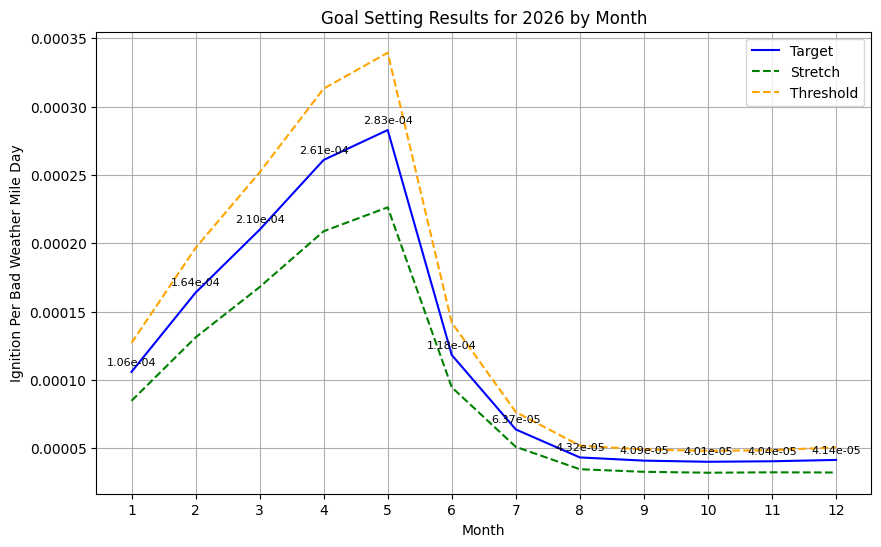

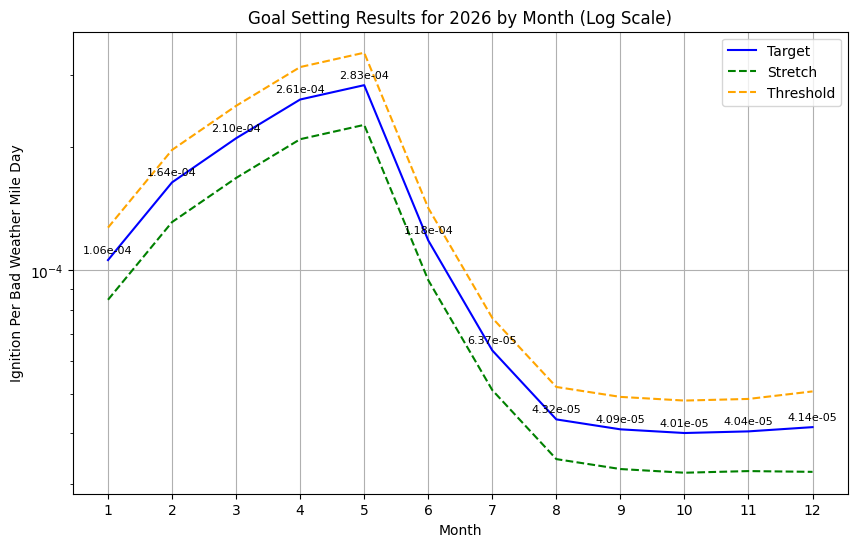

In [14]:
# merge ignitions and distribution data
option1_df = ignitions.merge(distribution_data_cumsum, on=['Year', 'Month'], how='left')
# keep only year 2020 and beyond
option1_df = option1_df[option1_df['Year'] >= 2020].reset_index(drop=True)
# for year 2025, replace Circuit Miles with historical_2025_full Circuit Miles
option1_df.loc[option1_df['Year'] == 2025, 'Circuit Miles'] = option1_df.loc[option1_df['Year'] == 2025].merge(historical_2025_full[['Month', 'Circuit Miles']], on='Month', how='left')['Circuit Miles_y'].values
# for each year, calculate cumuluative Circuit Miles and Actual Ignitions
for yr in range(2020, 2026):
    year_data = option1_df[option1_df['Year'] == yr].reset_index(drop=True)
    year_data['Cumulative Circuit Miles'] = year_data['Circuit Miles'].cumsum()
    year_data['Cumulative Actual Ignitions'] = year_data['Actual Ignitions'].cumsum()
    option1_df.loc[option1_df['Year'] == yr, 'Cumulative Circuit Miles'] = year_data['Cumulative Circuit Miles'].values
    option1_df.loc[option1_df['Year'] == yr, 'Cumulative Actual Ignitions'] = year_data['Cumulative Actual Ignitions'].values
# create a range for 2020-2024
res_table = []
weights = [0.05, 0.05, 0.1, 0.1, 0.7]
# loop through each month 1-12
for m in range(1, 13):
    # filter for month
    month_data = option1_df[option1_df['Month'] == m].reset_index(drop=True)
    # loop through each year from 2020 to 2025
    mini_year_table = []
    for yr in range(2021, 2026):
        # filter for year
        year_data = month_data[month_data['Year'] == yr].reset_index(drop=True)
        actual_ignitions = year_data['Cumulative Actual Ignitions'].values[0]
        circuit_miles = year_data['Cumulative Circuit Miles'].values[0]
        mini_year_table.append({
            'Year': yr,
            'Actual Ignitions': actual_ignitions,
            'Circuit Miles': circuit_miles
        })
    mini_year_df = pd.DataFrame(mini_year_table)
    # calculate weighted average for Target using weights
    weighted_avg = (mini_year_df['Actual Ignitions'] * weights).sum() / (mini_year_df['Circuit Miles'] * weights).sum()
    target = weighted_avg
    # subtract 20% for Stretch
    stretch = target * 0.8
    # add 20% for Threshold
    threshold = target * 1.2
    res_table.append({
        'Month': m,
        'Target': target,
        'Stretch': stretch,
        'Threshold': threshold
    })
res_df = pd.DataFrame(res_table)
# replace inf in res_df with max target value times 1.1
res_df['Target'] = res_df['Target'].replace(np.inf, res_df['Target'].replace(np.inf, 0).max() * 1.1)
res_df['Stretch'] = res_df['Stretch'].replace(np.inf, res_df['Stretch'].replace(np.inf, 0).max() * 1.1)
res_df['Threshold'] = res_df['Threshold'].replace(np.inf, res_df['Threshold'].replace(np.inf, 0).max() * 1.1)
# locate where Month is 12, change Target to 4.14e-05, Threshold to 5.06e-05, Stretch to 3.22e-05
res_df.loc[res_df['Month'] == 12, 'Target'] = 4.14e-05
res_df.loc[res_df['Month'] == 12, 'Threshold'] = 5.06e-05
res_df.loc[res_df['Month'] == 12, 'Stretch'] = 3.22e-05
# for nan, use backfill method
res_df.ffill(inplace=True)
# plot the merged_df
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(res_df['Month'], res_df['Target'], color='blue', label='Target')
ax.plot(res_df['Month'], res_df['Stretch'], color='green', linestyle='--', label='Stretch')
ax.plot(res_df['Month'], res_df['Threshold'], color='orange', linestyle='--', label='Threshold')
# # # make plot log scale for y axis
# ax.set_yscale('log')
# annotate the actual
for i, txt in enumerate(res_df['Target']):
    ax.annotate(f"{txt:.2e}", (res_df['Month'][i], res_df['Target'][i]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=8)
ax.set_title('Goal Setting Results for 2026 by Month')
# get x ticks
ax.set_xticks(range(1, 13))
ax.set_xlabel('Month')
ax.set_ylabel('Ignition Per Bad Weather Mile Day')
# add legend
ax.legend()
plt.grid()
# make a second plot that is log scale for y axis
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(res_df['Month'], res_df['Target'], color='blue', label='Target')
ax.plot(res_df['Month'], res_df['Stretch'], color='green', linestyle='--', label='Stretch')
ax.plot(res_df['Month'], res_df['Threshold'], color='orange', linestyle='--', label='Threshold')
# make plot log scale for y axis
ax.set_yscale('log')
# annotate the actual
for i, txt in enumerate(res_df['Target']):
    ax.annotate(f"{txt:.2e}", (res_df['Month'][i], res_df['Target'][i]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=8)
ax.set_title('Goal Setting Results for 2026 by Month (Log Scale)')
# get x ticks
ax.set_xticks(range(1, 13))
ax.set_xlabel('Month')
ax.set_ylabel('Ignition Per Bad Weather Mile Day')
# add legend
ax.legend()
plt.grid()
# multiply Target, Threshold, Ratio_Cleaned and Threshold by 1e5 for better visualization, also Stretch
res_df['Stretch'] = res_df['Stretch'] * 1e5
res_df['Target'] = res_df['Target'] * 1e5
res_df['Threshold'] = res_df['Threshold'] * 1e5
res_df

In [10]:
option1_df.to_excel("//sce.eix.com/workgroup/SPE_DSA/Charles/IgnitionGoalSettingMidput/Option1_GoalSettingResults_2020-2025_WithCumulative.xlsx", index=False)

    Year  Month  Actual Ignitions  Circuit Miles  Cumulative Circuit Miles  \
0   2025      1                 4   39776.979657              39776.979657   
1   2025      2                 2      22.584676              39799.564334   
2   2025      3                 1       0.000000              39799.564334   
3   2025      4                 1       0.000000              39799.564334   
4   2025      5                 3    7539.654346              47339.218679   
5   2025      6                 6  105162.315511             152501.534190   
6   2025      7                 3  173091.084684             325592.618874   
7   2025      8                 5  285264.519125             610857.137999   
8   2025      9                 3   88519.419324             699376.557324   
9   2025     10                 1    4014.270482             703390.827806   
10  2025     11                 0      39.115242             703429.943048   
11  2025     12                 0       0.000000             703

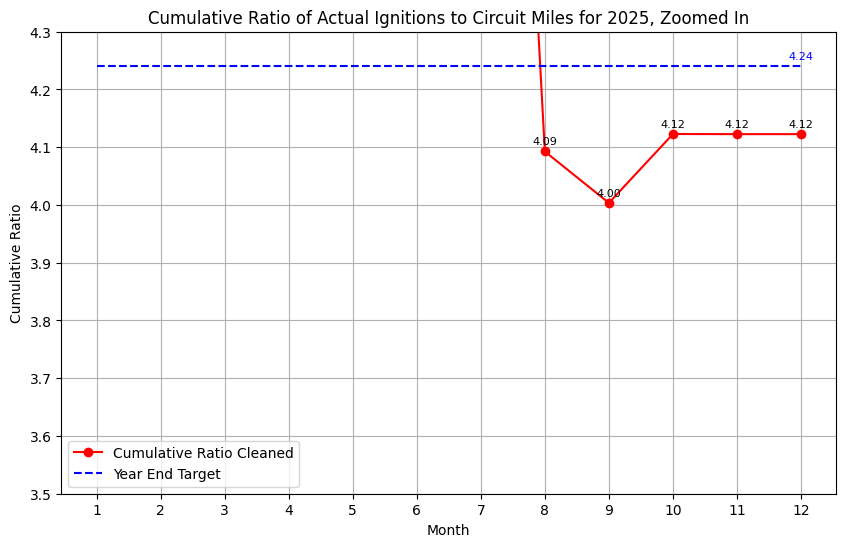

,Year,Month,Actual Ignitions,Circuit Miles,Cumulative Circuit Miles,Cumulative Actual Ignitions,Cumulative Ratio,Cumulative Ratio Cleaned,YE_Target
0,2025,1,4,39776.979657,39776.979657,4.0,10.056068,10.056068,4.24
1,2025,2,2,22.584676,39799.564334,6.0,15.075542,15.075542,4.24
2,2025,3,1,0.000000,39799.564334,7.0,17.588132,17.588132,4.24
3,2025,4,1,0.000000,39799.564334,8.0,20.100723,20.100723,4.24
4,2025,5,3,7539.654346,47339.218679,11.0,23.236547,23.236547,4.24
5,2025,6,6,105162.315511,152501.534190,17.0,11.147429,11.147429,4.24
6,2025,7,3,173091.084684,325592.618874,20.0,6.142645,6.142645,4.24
7,2025,8,5,285264.519125,610857.137999,25.0,4.092610,4.092610,4.24
8,2025,9,3,88519.419324,699376.557324,28.0,4.003566,4.003566,4.24
9,2025,10,1,4014.270482,703390.827806,29.0,4.122886,4.122886,4.24


In [16]:
# merge ignitions and distribution data
option1_df = ignitions.merge(distribution_data_cumsum, on=['Year', 'Month'], how='left')
# keep only year 2015 and beyond
option1_df = option1_df[option1_df['Year'] >= 2015].reset_index(drop=True)
# for year 2025, replace Circuit Miles with historical_2025_full Circuit Miles
option1_df.loc[option1_df['Year'] == 2025, 'Circuit Miles'] = option1_df.loc[option1_df['Year'] == 2025].merge(historical_2025_full[['Month', 'Circuit Miles']], on='Month', how='left')['Circuit Miles_y'].values
# for each year, calculate cumuluative Circuit Miles and Actual Ignitions
for yr in range(2015, 2026):
    year_data = option1_df[option1_df['Year'] == yr].reset_index(drop=True)
    year_data['Cumulative Circuit Miles'] = year_data['Circuit Miles'].cumsum()
    year_data['Cumulative Actual Ignitions'] = year_data['Actual Ignitions'].cumsum()
    option1_df.loc[option1_df['Year'] == yr, 'Cumulative Circuit Miles'] = year_data['Cumulative Circuit Miles'].values
    option1_df.loc[option1_df['Year'] == yr, 'Cumulative Actual Ignitions'] = year_data['Cumulative Actual Ignitions'].values
# create a range for 2020-2024
res_table = []
# get a copy of option_1df for just 2025
year_filter = 2025
option1_2025_df = option1_df[option1_df['Year'] == year_filter].reset_index(drop=True)
option1_2025_df['Cumulative Ratio'] = option1_2025_df['Cumulative Actual Ignitions'] / option1_2025_df['Cumulative Circuit Miles']
option1_2025_df['Cumulative Ratio'] = option1_2025_df['Cumulative Ratio'].fillna(0)
print(option1_2025_df)
# rescale Cumulative Ratio by 1e5
option1_2025_df['Cumulative Ratio'] = option1_2025_df['Cumulative Ratio'] * 1e5
# make a cleaned copy of Cumulative Ratio where inf is replaced with max value, nan with 0
option1_2025_df['Cumulative Ratio Cleaned'] = option1_2025_df['Cumulative Ratio'].replace(np.inf, option1_2025_df['Cumulative Ratio'].replace(np.inf, 0).max())
option1_2025_df['YE_Target'] = 4.24
# plot cumulative ratio over months
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_title(f'Cumulative Ratio of Actual Ignitions to Circuit Miles for {year_filter}, Zoomed In')
ax.set_xlabel('Month')
ax.set_ylabel('Cumulative Ratio')
ax.plot(option1_2025_df['Month'], option1_2025_df['Cumulative Ratio Cleaned'], marker='o', color='red', label='Cumulative Ratio Cleaned')
# plot YE_Target as a dashed blue line
ax.plot(option1_2025_df['Month'], option1_2025_df['YE_Target'], linestyle='dashed', color='blue', label='Year End Target')
# set y limit to 4.3
ax.set_ylim(3.5, 4.3)
# add ticks for x axis
ax.set_xticks(range(1, 13))
# add a legend 
ax.legend()
# annotate each point with its value
for i, txt in enumerate(option1_2025_df['Cumulative Ratio']):
    ax.annotate(f"{txt:.2f}", (option1_2025_df['Month'][i], option1_2025_df['Cumulative Ratio Cleaned'][i]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=8)
ax.annotate(f"{option1_2025_df['YE_Target'].values[0]:.2f}", (option1_2025_df['Month'].values[-1], option1_2025_df['YE_Target'].values[-1]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=8, color='blue')
plt.grid()
plt.show()
option1_2025_df